# The Paradox of Water — Reproducible Scientific Visualizations

**Source:** FAO AQUASTAT · 2000–2023. This notebook generates Figures 1–5 for the accompanying blog from the source records, **not from AI-generated images**.

**Files:** `aquastat_source_data.csv` (included alongside notebook), or the original AQUASTAT Excel file (the CSV was extracted without modifying the observations). Maps require a Natural Earth country boundary dataset, downloaded on first run. Outputs: PNG, SVG and audit CSV files in `water_figures/`.

**Method:** 2023 maps use all reported values. Longitudinal analyses use complete 2000–2023 records for both variables, excluding Kuwait due to its discontinuous stress series. Trend classification and scatter use 2023/2000 endpoints; line and radial colors use the 2000–2004 median baseline. No smoothing or interpolation.

**Las cinco figuras se muestran directamente en este notebook, incluso antes de ejecutar las celdas.** Las vistas previas están incrustadas en el archivo y no dependen de rutas externas. Al ejecutar las celdas de Python se regeneran las figuras longitudinales y el gráfico radial desde los datos. Los mapas de referencia también se muestran; para regenerarlos se necesita el archivo de límites geográficos indicado en el notebook.


In [13]:
# Run in Jupyter/Colab if dependencies are missing:
# %pip install pandas numpy matplotlib geopandas pyogrio requests nbformat openpyxl
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize, BoundaryNorm, ListedColormap
from matplotlib.patches import Rectangle
from matplotlib.cm import ScalarMappable
OUT=Path('water_figures'); OUT.mkdir(exist_ok=True)
CSV=Path('aquastat_source_data.xlsx')
assert CSV.exists(), 'Place aquastat_source_data.xlsx alongside this notebook.'

# Inspect sheet names and load the correct data sheet (typically the second sheet or one named 'Data')
xl = pd.ExcelFile(CSV)
sheet_name = xl.sheet_names[1] if len(xl.sheet_names) > 1 else xl.sheet_names[0]
df = pd.read_excel(CSV, sheet_name=sheet_name)

df['Value']=pd.to_numeric(df['Value'],errors='coerce'); df['Year']=pd.to_numeric(df['Year'],errors='coerce')
STRESS='SDG 6.4.2'; EFF='SDG 6.4.1'
df['indicator']=np.where(df['Variable'].str.contains(STRESS,regex=False),'stress',np.where(df['Variable'].str.contains(EFF,regex=False),'efficiency','other'))
df=df[(df.indicator!='other') & df.Year.between(2000,2023) & df.Value.notna()].copy()
print('Records:',len(df),'Areas:',df.Area.nunique()); print(df.groupby('indicator').size())

Records: 7850 Areas: 181
indicator
efficiency    3682
stress        4168
dtype: int64


In [14]:
# Explicit sample construction and verification
assert not df.duplicated(['Area','Year','indicator']).any(), 'Duplicate area/year/indicator records found'
wide=df.pivot(index=['Area','Year'],columns='indicator',values='Value')
full=wide.unstack('Year')
complete=full.notna().all(axis=1)
areas=sorted(complete[complete].index.tolist())
print('Complete sample before exclusion:',len(areas))
assert 'Kuwait' in areas, 'Check source/sample: Kuwait not present in complete records'
areas.remove('Kuwait')
assert len(areas)==105, f'Expected 105 countries, found {len(areas)}; inspect source data'
long=wide.loc[areas].reset_index()
assert len(long)==105*24 and (long[['stress','efficiency']]>0).all().all()
latest=df[df.Year==2023]
print('2023 map counts:',latest.groupby('indicator').Area.nunique().to_dict())
assert latest[latest.indicator=='stress'].Area.nunique()==179
assert latest[latest.indicator=='efficiency'].Area.nunique()==170
assert len(long)*2==5040
long.to_csv(OUT/'longitudinal_105_annual_values.csv',index=False)

Complete sample before exclusion: 106
2023 map counts: {'efficiency': 170, 'stress': 179}


In [15]:
# Country-level baselines, endpoints and categories
p=long.set_index(['Area','Year'])[['stress','efficiency']].sort_index()
base=p.loc[p.index.get_level_values('Year').isin(range(2000,2005))].groupby('Area').median()
a=p.xs(2000,level='Year'); z=p.xs(2023,level='Year')
changes=np.log2(z/a); changes.columns=['stress_change','efficiency_change']
changes['stress_direction']=np.sign(z.stress-a.stress).astype(int)
changes['efficiency_direction']=np.sign(z.efficiency-a.efficiency).astype(int)
print('Stress direction:',changes.stress_direction.value_counts().sort_index().to_dict())
print('Efficiency direction:',changes.efficiency_direction.value_counts().sort_index().to_dict())
print('Cross-tab:\n',pd.crosstab(changes.efficiency_direction,changes.stress_direction))
changes.to_csv(OUT/'endpoint_changes_and_classifications.csv')
for country in ['Saudi Arabia','United Arab Emirates']:
    if country in a.index:
        print(country, {k:round((z.loc[country,k]/a.loc[country,k]-1)*100,1) for k in ['stress','efficiency']})

Stress direction: {-1: 38, 0: 5, 1: 62}
Efficiency direction: {-1: 10, 1: 95}
Cross-tab:
 stress_direction      -1   0   1
efficiency_direction            
-1                     2   0   8
 1                    36   5  54
Saudi Arabia {'stress': np.float64(18.8), 'efficiency': np.float64(69.3)}
United Arab Emirates {'stress': np.float64(-7.6), 'efficiency': np.float64(40.4)}


## Figures 1–2 — Global maps in 2023

The five color categories represent **country percentiles**, not equal intervals of the indicator. Ranked tables use all reported 2023 observations. Country boundaries are from Natural Earth; matching by country name requires auditing. Unmatched country names are exported and **not silently assigned to the wrong country**. Small territories may not have polygons.

In [16]:
# Natural Earth 110m GeoJSON (download once; network required).
import json, urllib.request
GEO=Path('naturalearth_admin0_110m.geojson')
if not GEO.exists():
    try:
        urllib.request.urlretrieve('https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson',GEO)
    except Exception as e:
        print('Download failed:',e,'\nProvide naturalearth_admin0_110m.geojson manually to create maps.')
import geopandas as gpd
world=gpd.read_file(GEO) if GEO.exists() else None
if world is not None: print('Boundary columns:',list(world.columns)[:24])

Boundary columns: ['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV']


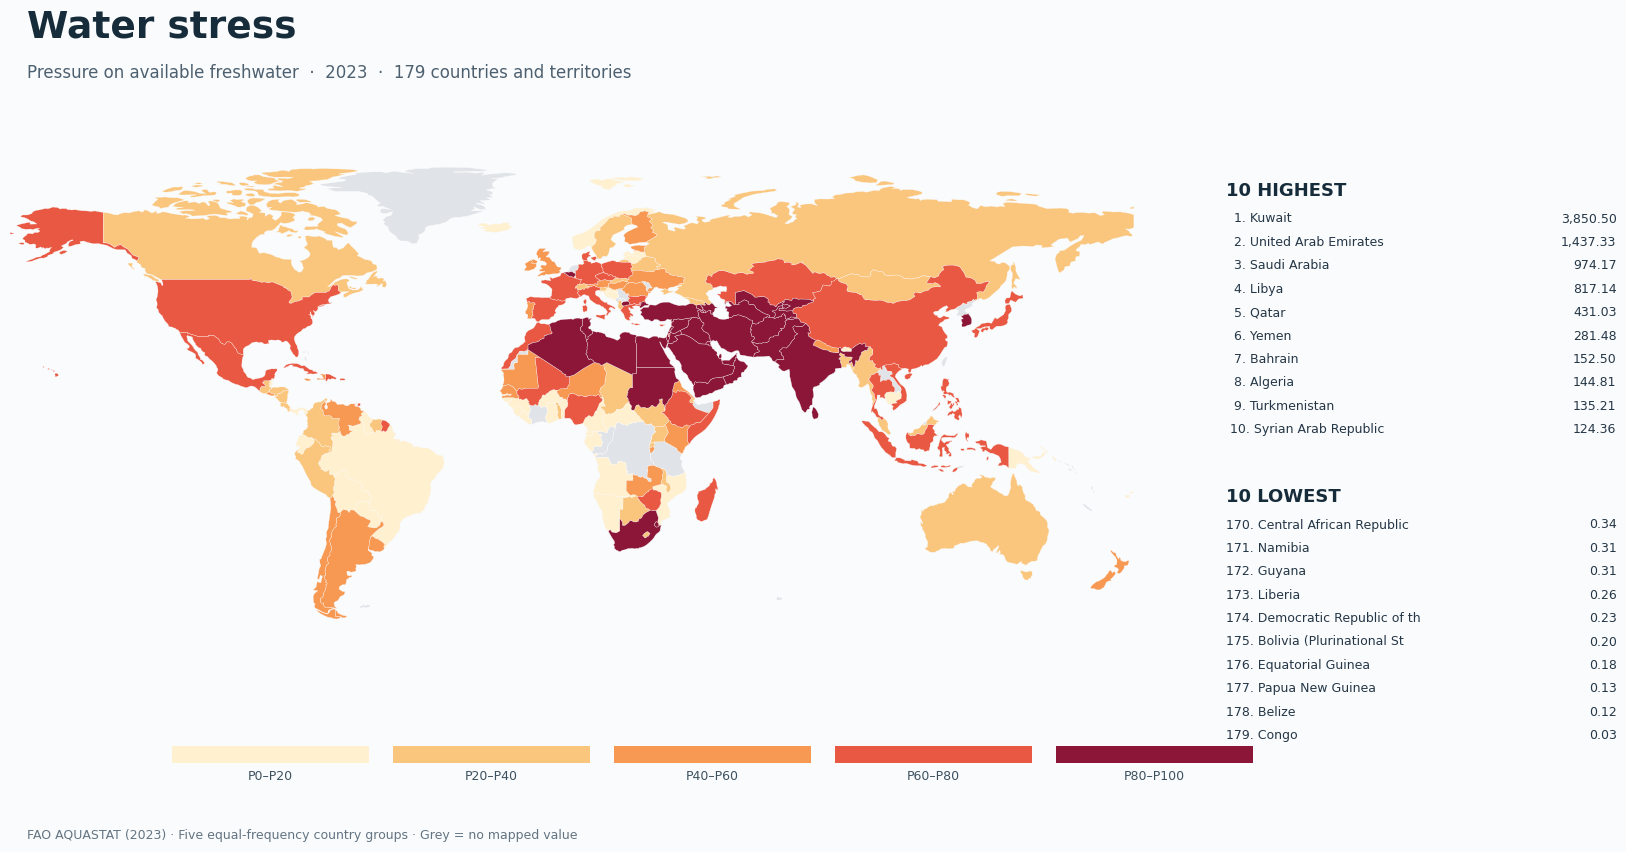

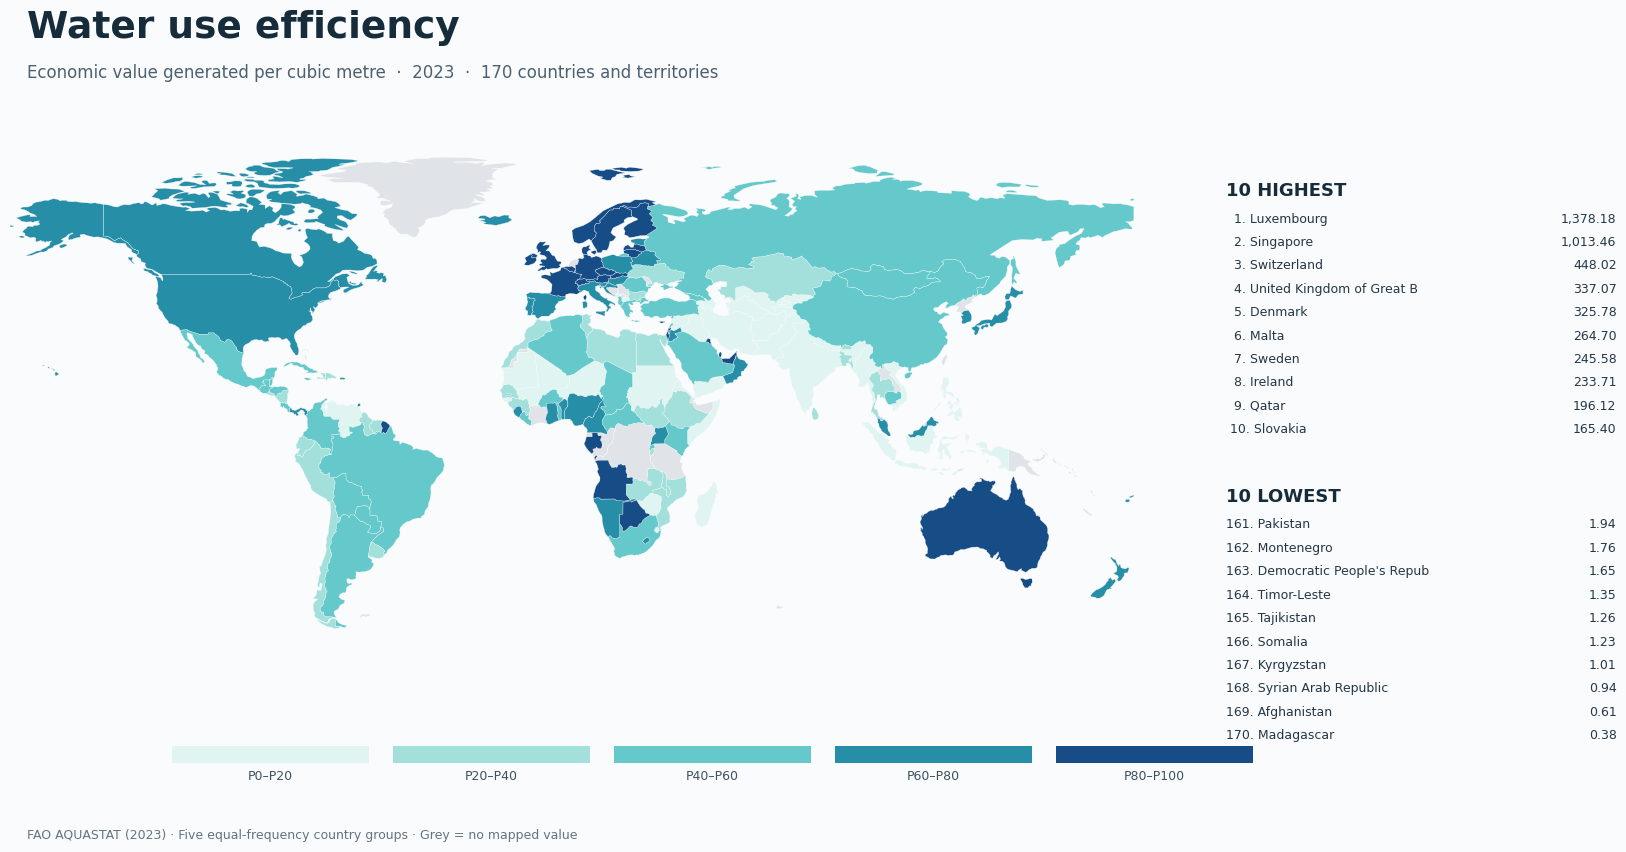

In [17]:
# Harmonize known Natural Earth / AQUASTAT naming differences.
ALIASES={'United States of America':'United States of America','United States':'United States of America',
'Russian Federation':'Russia','Viet Nam':'Vietnam','Iran (Islamic Republic of)':'Iran',
'Bolivia (Plurinational State of)':'Bolivia','Venezuela (Bolivarian Republic of)':'Venezuela',
'Syrian Arab Republic':'Syria','United Republic of Tanzania':'Tanzania',
'United Kingdom of Great Britain and Northern Ireland':'United Kingdom',
'Republic of Korea':'South Korea','Korea, Republic of':'South Korea',
'Democratic Republic of the Congo':'Dem. Rep. Congo','DR Congo':'Dem. Rep. Congo',
'Congo':'Congo','Czechia':'Czechia','Türkiye':'Turkey','Turkey':'Turkey',
'United Arab Emirates':'United Arab Emirates','Lao People’s Democratic Republic':'Laos',
'Côte d’Ivoire':'Ivory Coast','Eswatini':'eSwatini'}

def map_2023(metric,title,subtitle,colors,filename):
    if world is None: return
    sub=latest[latest.indicator==metric][['Area','Value']].drop_duplicates('Area').copy()
    sub['match']=sub.Area.replace(ALIASES)
    geo=world.copy()
    # Natural Earth uses ADMIN; name is a backup.
    namecol='ADMIN' if 'ADMIN' in geo.columns else 'name'
    geo['match']=geo[namecol]
    # Manual aliasing for Natural Earth names where needed.
    geo['match']=geo['match'].replace({'United States of America':'United States of America'})
    joined=geo.merge(sub[['match','Value']],on='match',how='left')
    unmatched=sub[~sub['match'].isin(geo['match'])]
    unmatched.to_csv(OUT/f'{metric}_2023_unmatched_areas.csv',index=False)
    q=np.quantile(sub.Value,[0,.2,.4,.6,.8,1]); q[0]-=1e-9; q[-1]+=1e-9
    joined['bin']=pd.cut(joined.Value,bins=q,labels=False,include_lowest=True,duplicates='drop')
    fig=plt.figure(figsize=(17,9),facecolor='#fafbfc'); ax=fig.add_axes([.035,.22,.68,.65]);ax.set_facecolor('#fafbfc')
    joined.plot(ax=ax,color='#e0e4e8',edgecolor='white',linewidth=.25)
    for i,c in enumerate(colors):
        part=joined[joined.bin==i]
        if len(part):part.plot(ax=ax,color=c,edgecolor='white',linewidth=.22)
    ax.set_axis_off(); ax.set_xlim(-170,190);ax.set_ylim(-60,85)
    fig.text(.045,.945,title,fontsize=27,fontweight='bold',color='#162c3b')
    fig.text(.045,.9,subtitle+'  ·  2023  ·  '+str(len(sub))+' countries and territories',fontsize=12,color='#4d6070')
    top=sub.sort_values('Value',ascending=False).reset_index(drop=True)
    for heading,offset,entries in [('10 HIGHEST',.77,top.head(10)),('10 LOWEST',.43,top.tail(10))]:
        fig.text(.75,offset,heading,fontsize=13,fontweight='bold',color='#162c3b')
        for j,(_,r) in enumerate(entries.iterrows()):
            rank=(j+1 if heading=='10 HIGHEST' else len(top)-9+j)
            fig.text(.75,offset-.03-j*.026,f'{rank:>3}. {r.Area[:25]}',fontsize=9,color='#253747')
            fig.text(.98,offset-.03-j*.026,f'{r.Value:,.2f}',fontsize=9,ha='right',color='#253747')
    for i,c in enumerate(colors):
        x=.13+i*.13;fig.add_artist(Rectangle((x,.14),.116,.018,transform=fig.transFigure,color=c,ec='none'))
        fig.text(x+.058,.12,f'P{i*20}–P{(i+1)*20}',ha='center',fontsize=9,color='#3c5160')
    fig.text(.045,.055,'FAO AQUASTAT (2023) · Five equal-frequency country groups · Grey = no mapped value',fontsize=9,color='#637482')
    fig.savefig(OUT/f'{filename}.png',dpi=220,facecolor=fig.get_facecolor(),bbox_inches='tight')
    fig.savefig(OUT/f'{filename}.svg',facecolor=fig.get_facecolor(),bbox_inches='tight');plt.show()
map_2023('stress','Water stress','Pressure on available freshwater', ['#fff0cf','#fac67d','#f79953','#e95842','#8b1638'],'figure_01_water_stress_map')
map_2023('efficiency','Water use efficiency','Economic value generated per cubic metre',['#e0f5f2','#a4e0db','#65c8ca','#278ea8','#174d86'],'figure_02_water_efficiency_map')

**Vista previa integrada — figure_01_stress_map_reference.png**

![Figures 1–2 — Maps (2023)](attachment:figure_01_stress_map_reference.png)

**Vista previa integrada — figure_02_efficiency_map_reference.png**

![Figures 1–2 — Maps (2023)](attachment:figure_02_efficiency_map_reference.png)

## Figure 3 — Two different stories of change

Each line corresponds to one country. The y-axis is `log₂(value / median(2000–2004))`. The **line color** is determined by the 2000-to-2023 endpoint direction, not by the baseline normalization.

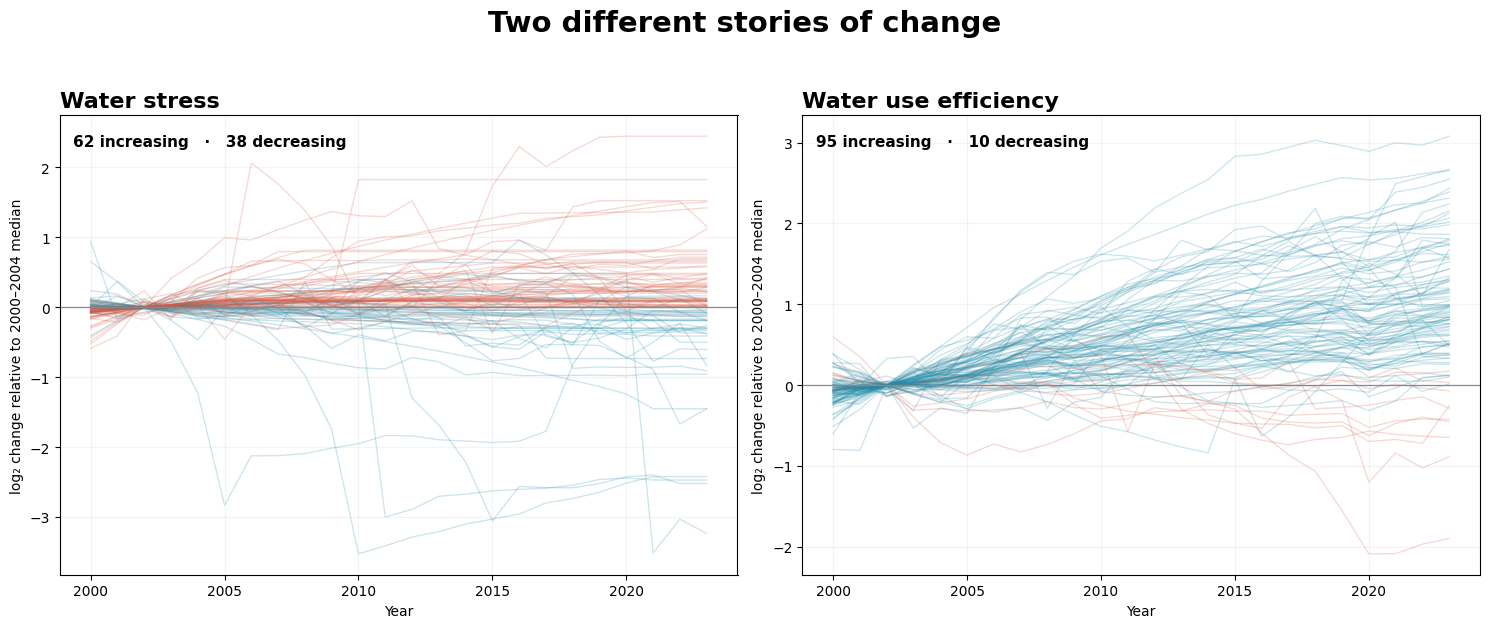

In [18]:
fig,axs=plt.subplots(1,2,figsize=(15,6),sharex=True,facecolor='white')
for ax,metric,ttl in zip(axs,['stress','efficiency'],['Water stress','Water use efficiency']):
    for area in areas:
        vals=p.loc[area,metric].sort_index();y=np.log2(vals/base.loc[area,metric])
        direction=changes.loc[area,metric+'_direction']
        color=('#d85b45' if direction>0 else '#248ca9' if direction<0 else '#a7aeb4') if metric=='stress' else ('#248ca9' if direction>0 else '#d85b45' if direction<0 else '#a7aeb4')
        ax.plot(vals.index,y,color=color,lw=.95,alpha=.23)
    ax.axhline(0,color='#7f8c96',lw=.9);ax.set_title(ttl,loc='left',fontweight='bold',fontsize=16)
    ax.grid(alpha=.14);ax.set_xlabel('Year');ax.set_ylabel('log₂ change relative to 2000–2004 median')
    counts=changes[metric+'_direction'].value_counts()
    ax.text(.02,.96,f'{counts.get(1,0)} increasing   ·   {counts.get(-1,0)} decreasing',transform=ax.transAxes,va='top',fontsize=11,fontweight='bold')
fig.suptitle('Two different stories of change',fontsize=21,fontweight='bold',y=1.04)
fig.tight_layout();fig.savefig(OUT/'figure_03_trajectories.png',dpi=240,bbox_inches='tight');fig.savefig(OUT/'figure_03_trajectories.svg',bbox_inches='tight');plt.show()

**Vista previa integrada — figure_03_trajectories.png**

![Figure 3 — Country trajectories](attachment:figure_03_trajectories.png)

## Figure 4 — The paradox

Each point represents one country; the axes show **endpoint** `log₂(2023 / 2000)` ratios. No country labels are drawn. Exact-zero cases remain on the axis.

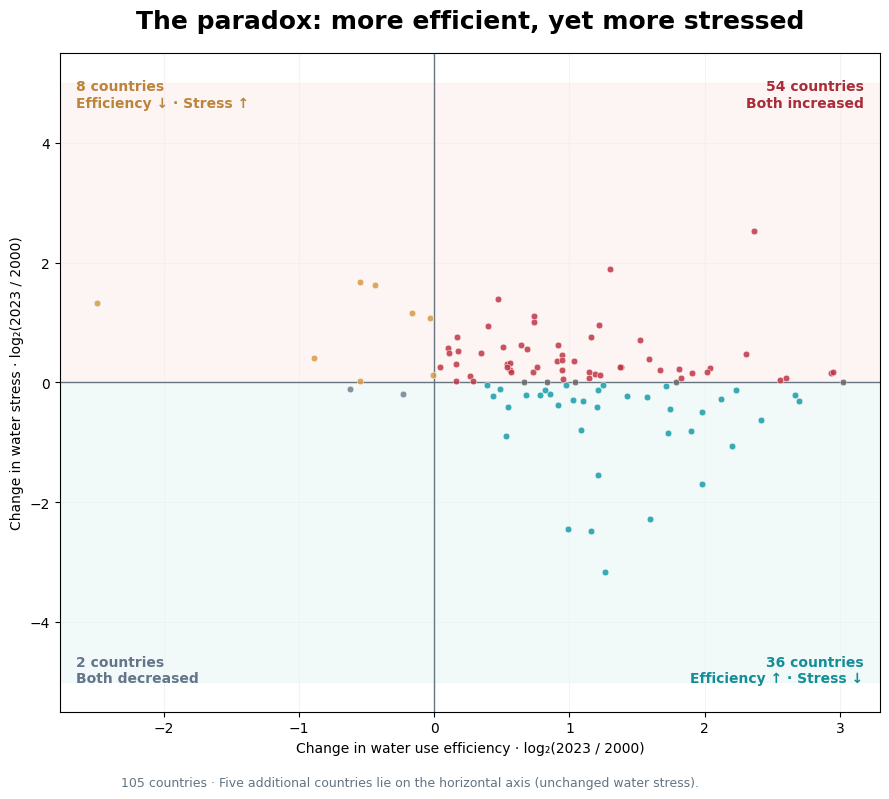

In [19]:
fig,ax=plt.subplots(figsize=(9,8),facecolor='white')
ax.axhspan(0,5,color='#fcecea',alpha=.5);ax.axhspan(-5,0,color='#eaf7f6',alpha=.6)
for area,r in changes.iterrows():
    x,y=r.efficiency_change,r.stress_change
    color=('#bf3543' if y>0 and x>0 else '#d99a45' if y>0 else '#159caa' if y<0 and x>0 else '#6f8293' if y<0 else '#666666')
    ax.scatter(x,y,s=23,color=color,alpha=.85,edgecolors='white',linewidths=.4,zorder=3)
ax.axhline(0,color='#667580',lw=1);ax.axvline(0,color='#667580',lw=1)
ax.grid(alpha=.14);ax.set_axisbelow(True)
ax.set_xlabel('Change in water use efficiency · log₂(2023 / 2000)');ax.set_ylabel('Change in water stress · log₂(2023 / 2000)')
ax.set_title('The paradox: more efficient, yet more stressed',fontsize=18,fontweight='bold',pad=18)
for x,y,txt,col,ha,va in [(.98,.96,'54 countries\nBoth increased','#a92c39','right','top'),(.98,.04,'36 countries\nEfficiency ↑ · Stress ↓','#128e99','right','bottom'),(.02,.96,'8 countries\nEfficiency ↓ · Stress ↑','#bc843b','left','top'),(.02,.04,'2 countries\nBoth decreased','#64748b','left','bottom')]:ax.text(x,y,txt,transform=ax.transAxes,ha=ha,va=va,color=col,fontweight='bold',fontsize=10)
fig.text(.14,.01,'105 countries · Five additional countries lie on the horizontal axis (unchanged water stress).',fontsize=9,color='#637482')
fig.tight_layout(rect=[0,.03,1,1]);fig.savefig(OUT/'figure_04_paradox.png',dpi=240,bbox_inches='tight');fig.savefig(OUT/'figure_04_paradox.svg',bbox_inches='tight');plt.show()

**Vista previa integrada — figure_04_paradox.png**

![Figure 4 — Efficiency and stress](attachment:figure_04_paradox.png)

## Figure 5 — Scientific radial disk (5,040 values)

Exactly **105 × 24** colored cells per half. The left half uses a warm stress palette and the right a cool efficiency palette. Both palettes are **monotonic in lightness from lower to higher relative change**, avoiding a misleading white midpoint. **A warm/cool color does not mean a country is dry/wet.** Values outside the legend's ±2 range are clipped for color display only; the underlying data are unchanged.

To align the 105 country spokes between halves, both sides use the same alphabetic country order starting at the top and proceeding around each semicircle. Countries are not arranged by magnitude.

Largest increases in water stress:


,area,stress_percent_change
0,Mali,476.680626
1,Nigeria,272.031835
2,Colombia,220.645882
3,Niger,207.037814
4,Zambia,162.992218
5,Venezuela (Bolivarian Republic of),149.711334
6,Madagascar,123.342508
7,Qatar,115.703192
8,South Africa,109.657439
9,Ireland,101.780026



Largest decreases in water stress:


,area,stress_percent_change
95,Estonia,-43.255408
96,Morocco,-44.634921
97,Brazil,-46.223299
98,Slovakia,-51.888731
99,Namibia,-65.645820
100,Ukraine,-69.053611
101,Burkina Faso,-79.395143
102,Bolivia (Plurinational State of),-81.705305
103,Ecuador,-82.176509
104,Ghana,-88.818432


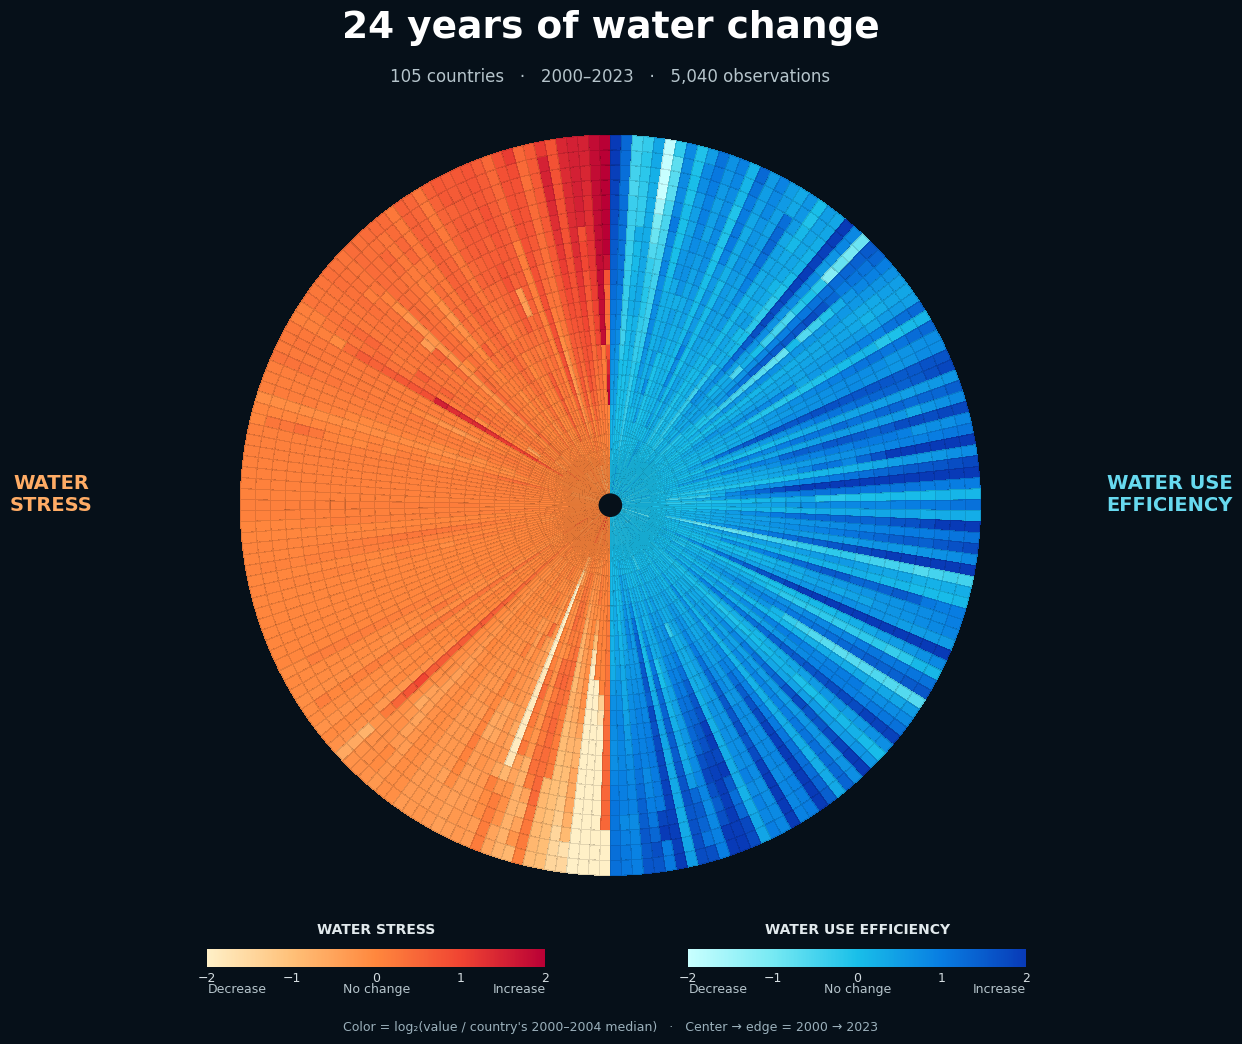

Verified: 5,040 source-derived radial cells
PNG saved: water_figures/figure_05_radial_scientific_ordered.png
SVG saved: water_figures/figure_05_radial_scientific_ordered.svg
Country ordering saved: water_figures/radial_country_order.csv


In [27]:
# ============================================================
# THE PARADOX OF WATER
# Scientific radial visualization
#
# 105 countries × 24 years × 2 indicators
# 5,040 observations
#
# Country ordering:
# Descending water stress change, 2000–2023
#
# Geometry:
# Same country mirrored across the vertical axis
#
# Colors:
# Water stress: yellow → orange → red
# Water use efficiency: cyan → blue
#
# Source: FAO AQUASTAT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable


# ============================================================
# 1. CONFIGURATION
# ============================================================

OUT = Path(OUT)
OUT.mkdir(parents=True, exist_ok=True)

YEARS = list(range(2000, 2024))

N = len(areas)

assert N == 105, (
    f"Expected 105 countries, found {N}"
)

assert len(YEARS) == 24

assert len(set(areas)) == N, (
    "Duplicate countries found."
)

# Background

BG = "#061019"

# Radial dimensions

R0 = 0.03
R1 = 1.00

# Logarithmic color-scale limits

VMIN = -2
VMAX = 2

norm = Normalize(
    vmin=VMIN,
    vmax=VMAX,
    clip=True
)


# ============================================================
# 2. COLOR PALETTES
# ============================================================

# Warm palette: water stress
# Pale yellow -> orange -> deep red

warm = LinearSegmentedColormap.from_list(
    "water_stress",
    [
        "#fff0c7",
        "#ffc078",
        "#ff873d",
        "#f04432",
        "#b90035"
    ],
    N=256
)

# Cool palette: water use efficiency
# Pale cyan -> turquoise -> deep blue

cool = LinearSegmentedColormap.from_list(
    "water_efficiency",
    [
        "#c8ffff",
        "#76e9f3",
        "#19bfe9",
        "#087de2",
        "#083ab7"
    ],
    N=256
)


# ============================================================
# 3. COUNTRY ORDERING
# ============================================================

# Countries are ranked according to the change in water
# stress between 2000 and 2023.
#
# Positive values: increasing stress
# Negative values: decreasing stress
#
# The same country order is used for both semicircles.

country_changes = []

for area in areas:

    stress_2000 = float(
        p.loc[(area, 2000), "stress"]
    )

    stress_2023 = float(
        p.loc[(area, 2023), "stress"]
    )

    if stress_2000 <= 0 or stress_2023 <= 0:
        raise ValueError(
            f"Invalid stress values for {area}"
        )

    log_change = np.log2(
        stress_2023 / stress_2000
    )

    percent_change = (
        stress_2023 / stress_2000 - 1
    ) * 100

    country_changes.append({
        "area": area,
        "stress_2000": stress_2000,
        "stress_2023": stress_2023,
        "stress_log2_change": log_change,
        "stress_percent_change": percent_change
    })

# Sort descending by change in water stress

country_changes = sorted(
    country_changes,
    key=lambda x: (
        -x["stress_log2_change"],
        x["area"]
    )
)

# Ordered country list

areas_ordered = [
    item["area"]
    for item in country_changes
]

# Export ordering

ordering_df = pd.DataFrame(
    country_changes
)

ordering_df.insert(
    0,
    "radial_position",
    range(1, N + 1)
)

ordering_df.to_csv(
    OUT / "radial_country_order.csv",
    index=False
)

print("Largest increases in water stress:")

display(
    ordering_df[
        [
            "area",
            "stress_percent_change"
        ]
    ].head(10)
)

print("\nLargest decreases in water stress:")

display(
    ordering_df[
        [
            "area",
            "stress_percent_change"
        ]
    ].tail(10)
)


# ============================================================
# 4. FIGURE
# ============================================================

fig = plt.figure(
    figsize=(13, 11),
    facecolor=BG
)

ax = fig.add_axes([
    0.17,
    0.17,
    0.66,
    0.70
])

ax.set_facecolor(BG)


# ============================================================
# 5. RADIAL VISUALIZATION
# ============================================================

total_cells = 0

for side, metric, cmap in [
    ("left", "stress", warm),
    ("right", "efficiency", cool)
]:

    polygons = []
    facecolors = []

    for j, area in enumerate(areas_ordered):

        # ----------------------------------------------------
        # Angular positions
        # ----------------------------------------------------
        #
        # LEFT:
        # 90° -> 270°
        #
        # RIGHT:
        # 90° -> -90°
        #
        # This mirrors country positions across the
        # vertical axis.

        if side == "left":

            a0 = np.deg2rad(
                90 + j * 180 / N
            )

            a1 = np.deg2rad(
                90 + (j + 1) * 180 / N
            )

        else:

            a0 = np.deg2rad(
                90 - (j + 1) * 180 / N
            )

            a1 = np.deg2rad(
                90 - j * 180 / N
            )

        # ----------------------------------------------------
        # Annual observations
        # ----------------------------------------------------

        for k, year in enumerate(YEARS):

            # Equal radial thickness for each year

            r0 = R0 + (
                R1 - R0
            ) * k / len(YEARS)

            r1 = R0 + (
                R1 - R0
            ) * (k + 1) / len(YEARS)

            # Original value

            value = float(
                p.loc[(area, year), metric]
            )

            # Baseline: median 2000–2004

            baseline = float(
                base.loc[area, metric]
            )

            if (
                not np.isfinite(value)
                or not np.isfinite(baseline)
                or value <= 0
                or baseline <= 0
            ):
                raise ValueError(
                    f"Invalid observation: "
                    f"{area}, {year}, {metric}"
                )

            # Logarithmic relative change

            log_change = np.log2(
                value / baseline
            )

            # Map to color

            color = cmap(
                norm(log_change)
            )

            # ------------------------------------------------
            # Polygon geometry
            # ------------------------------------------------

            polygon = [
                (
                    r0 * np.cos(a0),
                    r0 * np.sin(a0)
                ),
                (
                    r1 * np.cos(a0),
                    r1 * np.sin(a0)
                ),
                (
                    r1 * np.cos(a1),
                    r1 * np.sin(a1)
                ),
                (
                    r0 * np.cos(a1),
                    r0 * np.sin(a1)
                )
            ]

            polygons.append(
                polygon
            )

            facecolors.append(
                color
            )

            total_cells += 1

    # --------------------------------------------------------
    # Draw semicircle
    # --------------------------------------------------------

    collection = PolyCollection(
        polygons,
        facecolors=facecolors,
        edgecolors=(0, 0, 0, 0.11),
        linewidths=0.10,
        antialiased=False
    )

    ax.add_collection(
        collection
    )


# ============================================================
# 6. CENTER AND AXES
# ============================================================

center = plt.Circle(
    (0, 0),
    R0,
    color=BG,
    zorder=10
)

ax.add_artist(
    center
)

ax.set_xlim(
    -1.04,
    1.04
)

ax.set_ylim(
    -1.04,
    1.04
)

ax.set_aspect(
    "equal"
)

ax.axis(
    "off"
)


# ============================================================
# 7. TITLE
# ============================================================

fig.text(
    0.5,
    0.945,
    "24 years of water change",
    ha="center",
    fontsize=27,
    color="white",
    fontweight="bold"
)

fig.text(
    0.5,
    0.905,
    f"{N} countries   ·   "
    f"2000–2023   ·   "
    f"{total_cells:,} observations",
    ha="center",
    fontsize=12,
    color="#b5c4cb"
)


# ============================================================
# 8. SIDE LABELS
# ============================================================

fig.text(
    0.07,
    0.53,
    "WATER\nSTRESS",
    ha="center",
    va="center",
    fontsize=14,
    color="#ffac65",
    fontweight="bold"
)

fig.text(
    0.93,
    0.53,
    "WATER USE\nEFFICIENCY",
    ha="center",
    va="center",
    fontsize=14,
    color="#67d9ef",
    fontweight="bold"
)


# ============================================================
# 9. COLOR LEGENDS
# ============================================================

legends = [
    (
        0.19,
        warm,
        "WATER STRESS"
    ),
    (
        0.56,
        cool,
        "WATER USE EFFICIENCY"
    )
]

for x, cmap, label in legends:

    cax = fig.add_axes([
        x,
        0.10,
        0.26,
        0.017
    ])

    sm = ScalarMappable(
        norm=norm,
        cmap=cmap
    )

    sm.set_array([])

    cb = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        ticks=[-2, -1, 0, 1, 2]
    )

    cb.ax.tick_params(
        colors="#d3dce0",
        labelsize=9,
        length=0
    )

    cb.outline.set_visible(
        False
    )

    fig.text(
        x + 0.13,
        0.13,
        label,
        ha="center",
        fontsize=10,
        color="#e1e9ec",
        fontweight="bold"
    )

    fig.text(
        x,
        0.077,
        "Decrease",
        ha="left",
        fontsize=9,
        color="#b5c4cb"
    )

    fig.text(
        x + 0.13,
        0.077,
        "No change",
        ha="center",
        fontsize=9,
        color="#b5c4cb"
    )

    fig.text(
        x + 0.26,
        0.077,
        "Increase",
        ha="right",
        fontsize=9,
        color="#b5c4cb"
    )


# ============================================================
# 10. METHODOLOGICAL NOTE
# ============================================================

fig.text(
    0.5,
    0.042,
    "Color = log₂(value / country's 2000–2004 median)"
    "   ·   Center → edge = 2000 → 2023",
    ha="center",
    fontsize=9,
    color="#9bb0bb"
)


# ============================================================
# 11. EXPORT
# ============================================================

png_path = (
    OUT / "figure_05_radial_scientific_ordered.png"
)

svg_path = (
    OUT / "figure_05_radial_scientific_ordered.svg"
)

fig.savefig(
    png_path,
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

fig.savefig(
    svg_path,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. VALIDATION
# ============================================================

expected_cells = (
    2 * N * len(YEARS)
)

assert (
    total_cells == expected_cells
), (
    f"Expected {expected_cells} cells, "
    f"found {total_cells}"
)

print(
    f"Verified: {total_cells:,} "
    "source-derived radial cells"
)

print(
    f"PNG saved: {png_path}"
)

print(
    f"SVG saved: {svg_path}"
)

print(
    "Country ordering saved:",
    OUT / "radial_country_order.csv"
)